# Questions 6 and 7: what does the typical home cost each month, and who can afford it?

**Mortgage share** is the monthly payment on the typical home over a month of median household income. The payment is
principal and interest on Zillow's ZHVI with 10% down, 30-year fixed at that month's Freddie Mac rate, plus property tax
at the metro's effective rate (ACS median real estate taxes ÷ ACS median owner home value, `property_tax_rate`).
Source: `gold.mart_metro_month`; helpers `mortgage_share_change()` and `affordable_share()` in `common.py`.

**Who can afford it** is the share of households whose income keeps that payment at 30% or less, from the ACS 1-year
income brackets (`gold.fct_income.households_by_income`), linear within a bracket. 2015 uses the 2015 brackets and
the 2015 average payment; the latest 12 months use the latest vintage's brackets.

Caveats: insurance and HOA fees are left out. The tax rate is what current owners pay on what they say their home is
worth; Florida's Save Our Homes cap and Texas's homestead cap keep long-time owners' bills low, so a new buyer there
likely pays more. ACS income lags about a year, so recent mortgage shares run a little high and the share who can
afford a little low, because the latest brackets are a year older than the payments they are compared with.

In [1]:
import common as c
from matplotlib.ticker import PercentFormatter

In [2]:
share = c.mortgage_share_change()
pi_only = c.mortgage_share_change(taxes=False)
share.assign(pi_only_latest=pi_only.latest_share)

,start_share,latest_share,change,pi_only_latest
metro,,,,
Seattle,0.273,0.461,0.188,0.410
Denver,0.246,0.380,0.134,0.350
Nashville,0.206,0.353,0.147,0.329
Phoenix,0.217,0.349,0.132,0.329
Orlando,0.217,0.341,0.124,0.305
Austin,0.264,0.340,0.075,0.277
Tampa,0.197,0.325,0.128,0.291
Charlotte,0.183,0.318,0.135,0.290
Raleigh,0.196,0.317,0.121,0.286


In [3]:
sens = {
    "10% down, with taxes": share,
    "10% down, principal and interest only": pi_only,
    "3.5% down (FHA)": c.mortgage_share_change(down=0.035),
    "20% down": c.mortgage_share_change(down=0.20),
    "from 2019": c.mortgage_share_change(start_year=2019),
}
{
    k: {
        "over 30%": int((v.latest_share > 0.30).sum()),
        "start max": round(v.start_share.max(), 3),
    }
    for k, v in sens.items()
}

{'10% down, with taxes': {'over 30%': 11, 'start max': np.float64(0.273)},
 '10% down, principal and interest only': {'over 30%': 5,
  'start max': np.float64(0.228)},
 '3.5% down (FHA)': {'over 30%': 11, 'start max': np.float64(0.289)},
 '20% down': {'over 30%': 6, 'start max': np.float64(0.248)},
 'from 2019': {'over 30%': 11, 'start max': np.float64(0.316)}}

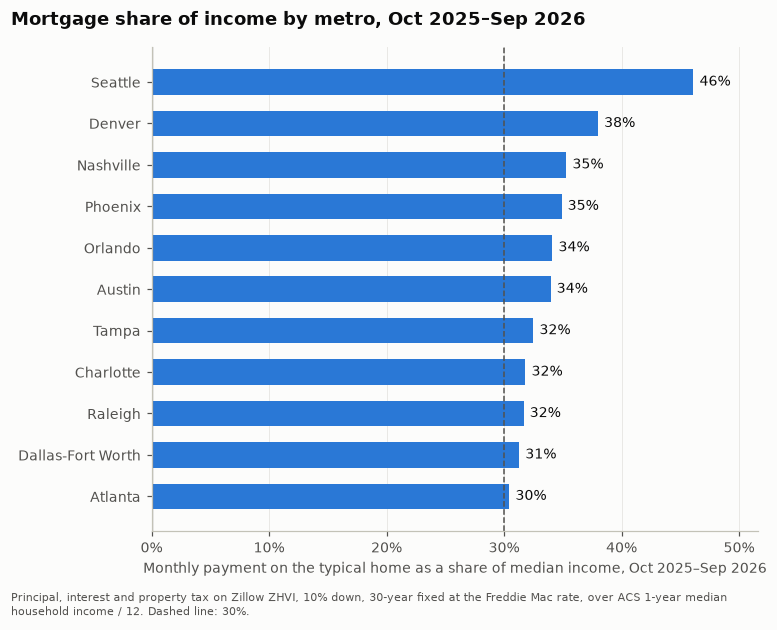

In [4]:
fig, ax = c.ranked_bars(share.latest_share, "{:.0%}", PercentFormatter(1, decimals=0))
ax.axvline(0.30, color=c.INK2, lw=1, ls="--")
ax.set_xlabel(
    f"Monthly payment on the typical home as a share of median income, {c.LATEST_12M}"
)
c.save(
    fig,
    "q6_mortgage_share",
    f"Mortgage share of income by metro, {c.LATEST_12M}",
    "Principal, interest and property tax on Zillow ZHVI, 10% down, 30-year fixed at the Freddie Mac rate, over ACS "
    "1-year median household income / 12. Dashed line: 30%.",
)

In [5]:
a = c.affordable_share()
a[
    [
        "start_income_needed",
        "start_share",
        "latest_income_needed",
        "latest_share",
        "change",
    ]
]

,start_income_needed,start_share,latest_income_needed,latest_share,change
metro,,,,,
Seattle,69934.449,0.537,184495.894,0.311,-0.226
Denver,58345.292,0.585,136445.137,0.396,-0.189
Nashville,40474.534,0.657,108329.437,0.428,-0.229
Phoenix,40964.437,0.635,105956.032,0.428,-0.207
Orlando,37418.637,0.633,96850.721,0.439,-0.195
Austin,60769.334,0.548,115954.100,0.449,-0.100
Tampa,32709.285,0.664,89516.228,0.473,-0.191
Charlotte,34917.300,0.686,94468.012,0.476,-0.210
Raleigh,44768.334,0.669,107339.438,0.484,-0.186


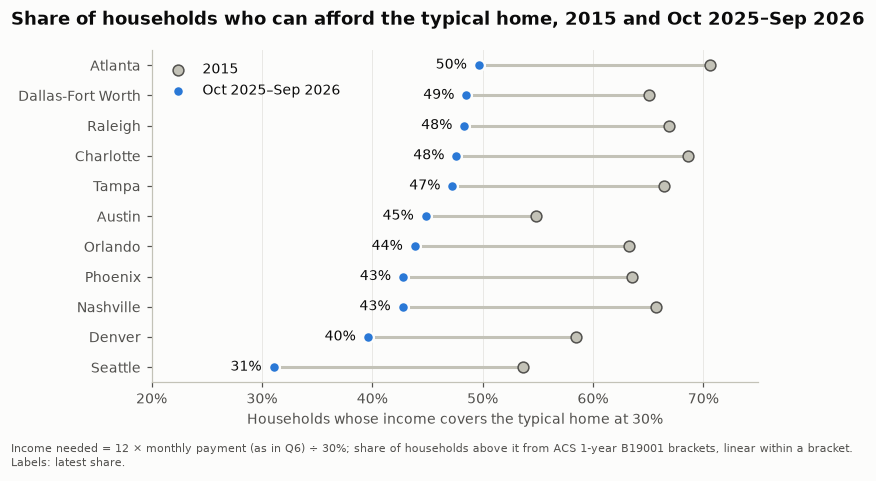

In [6]:
fig, ax = c.plt.subplots(figsize=(7, 4))
y = range(len(a))
ax.hlines(list(y), a.latest_share, a.start_share, color=c.MUTED, lw=2, zorder=2)
ax.scatter(
    a.start_share, y, s=50, color=c.MUTED, edgecolor=c.INK2, zorder=3, label="2015"
)
ax.scatter(
    a.latest_share,
    y,
    s=50,
    color=c.BLUE,
    edgecolor=c.SURFACE,
    linewidth=1.5,
    zorder=3,
    label=c.LATEST_12M,
)
for i, (m, row) in enumerate(a.iterrows()):
    ax.annotate(
        f"{row.latest_share:.0%}",
        (row.latest_share, i),
        xytext=(-8, 0),
        textcoords="offset points",
        ha="right",
        va="center",
        color=c.INK,
    )
ax.set_yticks(list(y), a.index)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Households whose income covers the typical home at 30%")
ax.set_xlim(0.2, 0.75)
ax.legend(loc="upper left", frameon=False)
c.save(
    fig,
    "q7_who_can_afford",
    f"Share of households who can afford the typical home, 2015 and {c.LATEST_12M}",
    "Income needed = 12 × monthly payment (as in Q6) ÷ 30%; share of households above it from ACS 1-year B19001 "
    "brackets, linear within a bracket. Labels: latest share.",
)

## Answer

In [7]:
top, low = share.iloc[0], share.iloc[-1]
print(
    f"Q6: with taxes the payment takes over 30% of median income in {(share.latest_share > 0.30).sum()} of {len(share)} "
    f"metros ({(share.start_share > 0.30).sum()} in 2015); {share.index[0]} is highest at {top.latest_share:.1%} "
    f"(from {top.start_share:.1%}), {share.index[-1]} lowest at {low.latest_share:.1%} (from {low.start_share:.1%}). "
    f"Principal and interest alone: {(pi_only.latest_share > 0.30).sum()} of {len(pi_only)}."
)
lo, hi = a.iloc[0], a.iloc[-1]
print(
    f"Q7: {a.index[0]} has the smallest share of households who can afford the typical home, {lo.latest_share:.0%} "
    f"(from {lo.start_share:.0%}; income needed ${lo.latest_income_needed:,.0f}); {a.index[-1]} the largest, "
    f"{hi.latest_share:.0%} (from {hi.start_share:.0%}). The share fell in {(a.change < 0).sum()} of {len(a)} metros; "
    f"median fall {-100 * a.change.median():.0f} points."
)

Q6: with taxes the payment takes over 30% of median income in 11 of 11 metros (0 in 2015); Seattle is highest at 46.1% (from 27.3%), Atlanta lowest at 30.5% (from 17.5%). Principal and interest alone: 5 of 11.
Q7: Seattle has the smallest share of households who can afford the typical home, 31% (from 54%; income needed $184,496); Atlanta the largest, 50% (from 71%). The share fell in 11 of 11 metros; median fall 19 points.
